# 02 · Data Understanding

**CRISP-DM phase 2** — describe, explore and verify the quality of the raw data.

Goal of this notebook: understand *what* is wrong with the data and *why*, **before** deciding how to clean it (phase 3).
Nothing here is persisted: any parsing done below is a temporary *exploration view*; the definitive cleaning lives in `src/data.py::clean()`.

Findings are summarised at the end.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
from data import load_config, load_raw

cfg = load_config()
RANGES = cfg["normal_ranges"]
SENSORS = ["temp_value", "vessel_pressure_bar", "refractive_index", "density_g_cm3",
           "ph_level", "mixing_torque_nm", "mass_flow_rate_kg_h"]
TARGET = cfg["target"]

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

## 1. First look

In [2]:
df = load_raw()
print(df.shape)
df.head()

(259200, 16)


,batch_id,event_timestamp,plant_location,plant_country,production_line_id,temp_value,temp_unit,vessel_pressure_bar,refractive_index,density_g_cm3,ph_level,mixing_torque_nm,mass_flow_rate_kg_h,stability_months,purity_grade,oxidation_risk_flag
0,BATCH-2023-000001,2023-06-02 03:05:00,Plant-05,Country-05,Fragrance-Synthesis-Reactor-02,82.3319,C,2.46575,1.465316,0.858032,NaN,11.97486,492.9606,21.090538,Industrial Grade,False
1,BATCH-2023-000002,2023-04-12 02:47:30,Plant-05,Country-05,Fragrance-Synthesis-Reactor-04,91.7391,C,2.24107,1.455938,0.876435,5.79598,11.85726,449.9237,21.202418,Industrial Grade,False
2,BATCH-2023-000003,2023-06-03 11:35:30,Plant-03,Country-03,Fragrance-Synthesis-Reactor-07,85.0281,C,2.34404,1.468787,0.848555,5.31299,12.02680,437.1050,22.515180,Industrial Grade,False
3,BATCH-2023-000004,2023-05-11 02:43:00,Plant-04,Country-04,Fragrance-Synthesis-Reactor-05,88.5994,C,2.10548,1.447880,0.871153,5.44103,11.67030,439.3516,19.843445,Technical Grade,True
4,BATCH-2023-000005,2023-05-19 13:12:30,Plant-01,Country-01,Fragrance-Synthesis-Reactor-01,82.4168,C,2.16206,NaN,0.840569,5.06367,12.24158,447.2072,24.464046,Industrial Grade,False


In [3]:
df.dtypes

batch_id               string[python]
event_timestamp        string[python]
plant_location               category
plant_country                category
production_line_id           category
temp_value                    float64
temp_unit                    category
vessel_pressure_bar           float64
refractive_index              float64
density_g_cm3                 float64
ph_level                      float64
mixing_torque_nm              float64
mass_flow_rate_kg_h           float64
stability_months              float64
purity_grade                 category
oxidation_risk_flag           boolean
dtype: object

## 2. Schema: documented vs. actual
The use case statement documents `reaction_temperature_celsius`; the file has `temp_value` + `temp_unit`.
It also contains an undocumented `plant_location`, and batch IDs use year **2023** (statement says 2026).

In [4]:
print("batch_id prefixes:", df["batch_id"].str[:10].value_counts().to_dict())
print("Duplicated rows:", df.duplicated().sum(), "| duplicated batch_id:", df["batch_id"].duplicated().sum())

batch_id prefixes: {'BATCH-2023': 259200}


Duplicated rows: 0 | duplicated batch_id: 0


## 3. Categorical columns: plants and reactors

In [5]:
# plant_location vs plant_country: is one redundant?
pd.crosstab(df["plant_location"], df["plant_country"])

plant_country,Country-01,Country-02,Country-03,Country-04,Country-05
plant_location,,,,,
Plant-01,70644,0,0,0,0
Plant-02,0,35140,0,0,0
Plant-03,0,0,48823,0,0
Plant-04,0,0,0,55858,0
Plant-05,0,0,0,0,48735


In [6]:
# Are reactor IDs unique machines, or repeated across plants?
pd.crosstab(df["production_line_id"], df["plant_location"])

plant_location,Plant-01,Plant-02,Plant-03,Plant-04,Plant-05
production_line_id,,,,,
Fragrance-Synthesis-Reactor-01,5598,6180,5753,5771,5753
Fragrance-Synthesis-Reactor-02,6140,6341,6425,6088,6452
Fragrance-Synthesis-Reactor-03,6122,7296,6486,6404,6463
Fragrance-Synthesis-Reactor-04,7070,7459,7116,7029,7057
Fragrance-Synthesis-Reactor-05,6950,7864,7537,7172,7428
Fragrance-Synthesis-Reactor-06,7015,0,7813,7426,7770
Fragrance-Synthesis-Reactor-07,7658,0,7693,7738,7812
Fragrance-Synthesis-Reactor-08,7840,0,0,8230,0
Fragrance-Synthesis-Reactor-09,8104,0,0,0,0


- `plant_country` is a 1:1 relabelling of `plant_location` → **redundant**.
- Reactor IDs are **reused across plants** (Plant-01 has 10 reactors, Plant-02 only 5). The physical machine is **plant × reactor** (37 in total, not the "10 reactors" of the statement).

In [7]:
df["reactor_key"] = df["plant_location"].astype(str) + " / R" + df["production_line_id"].astype(str).str[-2:]
print("Distinct physical reactors:", df["reactor_key"].nunique())

Distinct physical reactors: 37


## 4. Timestamps

In [8]:
ts = df["event_timestamp"]
fmt = np.select(
    [ts.str.match(r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$"),
     ts.str.match(r"^\d{2}/\d{2}/\d{4}$"),
     ts.str.match(r"^[A-Z][a-z]{2} \d{1,2}, \d{4}$")],
    ["ISO  (YYYY-MM-DD hh:mm:ss)", "Slash (NN/NN/YYYY)", "Text (Mon d, YYYY)"],
    default="other",
)
df["ts_format"] = fmt
df["ts_format"].value_counts()

ts_format
ISO  (YYYY-MM-DD hh:mm:ss)    234093
Slash (NN/NN/YYYY)             13024
Text (Mon d, YYYY)             12083
Name: count, dtype: int64

Three formats, no unparseable rows. The slash format is potentially ambiguous (`dd/mm` or `mm/dd`?).
Since ISO dates cover April–June only, the *month* field must be 4, 5 or 6:

In [9]:
parts = ts[df["ts_format"].str.startswith("Slash")].str.split("/", expand=True).astype(int)
print("1st field range:", parts[0].min(), "-", parts[0].max())
print("2nd field values:", sorted(parts[1].unique()))

1st field range: 1 - 31
2nd field values: [np.int64(4), np.int64(5), np.int64(6)]


The 2nd field only takes values 4–6 and the 1st goes up to 31 → the format is **`dd/mm/yyyy`**, without ambiguity.
Note: slash and text formats carry **no time of day** (date only) → analyses will be done at **daily** granularity.

In [10]:
# Temporary exploration view of the date (definitive parsing in clean())
date = pd.to_datetime(ts, format="%Y-%m-%d %H:%M:%S", errors="coerce")
is_slash = df["ts_format"].str.startswith("Slash")
date = date.fillna(pd.to_datetime(ts.where(is_slash), format="%d/%m/%Y", errors="coerce"))
date = date.fillna(pd.to_datetime(ts.where(~is_slash), format="%b %d, %Y", errors="coerce"))
df["date"] = date.dt.floor("D")
print("Unparsed:", df["date"].isna().sum(), "| range:", df["date"].min().date(), "->", df["date"].max().date(),
      "| days:", df["date"].nunique())

Unparsed: 0 | range: 2023-04-01 -> 2023-06-29 | days: 90


In [11]:
# Are the date-only formats spread evenly, or concentrated somewhere?
pd.crosstab(df["plant_location"], df["ts_format"], normalize="index").round(3)

ts_format,ISO (YYYY-MM-DD hh:mm:ss),Slash (NN/NN/YYYY),"Text (Mon d, YYYY)"
plant_location,,,
Plant-01,0.902,0.051,0.046
Plant-02,0.906,0.048,0.046
Plant-03,0.903,0.050,0.047
Plant-04,0.903,0.050,0.047
Plant-05,0.903,0.050,0.046


## 5. Missing values

In [12]:
miss = df[SENSORS].isna()
(miss.mean() * 100).round(2).rename("% missing").to_frame()

,% missing
temp_value,8.94
vessel_pressure_bar,8.86
refractive_index,8.86
density_g_cm3,8.89
ph_level,8.85
mixing_torque_nm,8.83
mass_flow_rate_kg_h,8.94


In [13]:
# Number of missing sensors per row
miss.sum(axis=1).value_counts().sort_index().rename("rows")

0    153331
1     79960
2     18116
3      2268
4       171
5        10
7      5344
Name: rows, dtype: int64

If each sensor failed independently with p ≈ 0.09, all 7 missing at once would happen ~0.09⁷ ≈ 5e-8 of the time (≈ 0 rows).
We see ~5.3k → a **separate mechanism**: complete logging failures of a batch, on top of individual sensor dropouts.

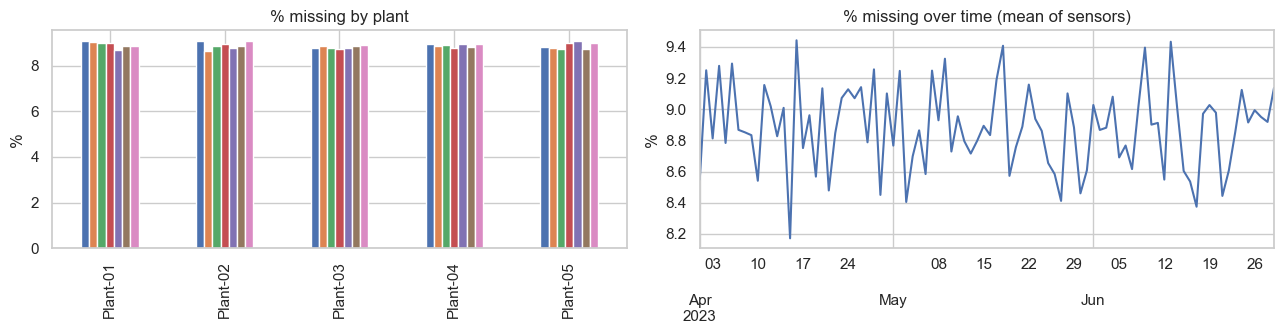

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
(miss.groupby(df["plant_location"], observed=True).mean() * 100).plot(kind="bar", ax=axes[0], legend=False)
axes[0].set(title="% missing by plant", ylabel="%", xlabel="")
(miss.groupby(df["date"]).mean().mean(axis=1) * 100).plot(ax=axes[1])
axes[1].set(title="% missing over time (mean of sensors)", ylabel="%", xlabel="")
plt.tight_layout(); plt.show()

In [15]:
# Does missingness relate to the target? (if not -> consistent with "missing completely at random")
rows = {c: [df.loc[miss[c], TARGET].mean(), df.loc[~miss[c], TARGET].mean()] for c in SENSORS}
all_miss = miss.all(axis=1)
rows["ALL sensors missing"] = [df.loc[all_miss, TARGET].mean(), df.loc[~all_miss, TARGET].mean()]
pd.DataFrame(rows, index=["stability | missing", "stability | present"]).T.round(3)

,stability | missing,stability | present
temp_value,21.517,21.533
vessel_pressure_bar,21.521,21.533
refractive_index,21.519,21.533
density_g_cm3,21.553,21.530
ph_level,21.510,21.534
mixing_torque_nm,21.518,21.533
mass_flow_rate_kg_h,21.507,21.534
ALL sensors missing,21.497,21.532


Missingness is **flat across plants and time** and the target is essentially the same whether a value is missing or not
→ consistent with **MCAR** (random sensor failures). This matters for phase 3: dropping or imputing should not bias results.

## 6. Impossible values (sentinels) and units

In [16]:
summary = []
for c in SENSORS:
    lo, hi = RANGES["reaction_temperature_celsius" if c == "temp_value" else c]
    x = df.loc[df["temp_unit"] != "F", c] if c == "temp_value" else df[c]
    out = x[(x < lo) | (x > hi)]
    summary.append({"sensor": c, "normal range": f"{lo}-{hi}", "n out of range": len(out),
                    "distinct out-of-range values": sorted(out.round(3).unique())[:6]})
pd.DataFrame(summary)

,sensor,normal range,n out of range,distinct out-of-range values
0,temp_value,75.0-100.0,507,[210.0]
1,vessel_pressure_bar,2.0-3.0,1053,"[-1.0, 1.989, 1.99, 1.991, 1.992, 1.993]"
2,refractive_index,1.43-1.49,0,[]
3,density_g_cm3,0.8-0.9,558,[860.0]
4,ph_level,5.0-6.0,8181,"[4.945, 4.946, 4.947, 4.948, 4.949, 4.95]"
5,mixing_torque_nm,9.0-12.5,3853,"[12.5, 12.501, 12.502, 12.503, 12.504, 12.505]"
6,mass_flow_rate_kg_h,380.0-520.0,456,"[520.0, 520.002, 520.005, 520.006, 520.009, 52..."


Two different kinds of out-of-range values:
1. **Error codes** — one exact, repeated, physically impossible value per sensor: pressure **−1**, density **860**, pH **14**, temperature **210 °C**. Typical of a failing sensor writing a default value.
2. **Marginal excursions** — continuous values *just* beyond the limits (pressure down to 1.989, pH 4.95–6.11, torque up to 12.56, flow up to 521.9). Physically plausible readings → real data, **not errors**.

In [17]:
print(df["temp_unit"].value_counts(dropna=False))
f = df.loc[df["temp_unit"] == "F", "temp_value"]
print("\n°F values converted to °C (excluding 410 °F):",
      ((f[f != 410] - 32) * 5 / 9).agg(["min", "max"]).round(2).to_dict())
print("410 °F =", round((410 - 32) * 5 / 9, 1), "°C  -> the same 210 °C error code, in Fahrenheit")

temp_unit
C      234524
NaN     23170
F        1506
Name: count, dtype: int64

°F values converted to °C (excluding 410 °F): {'min': 79.27, 'max': 92.09}
410 °F = 210.0 °C  -> the same 210 °C error code, in Fahrenheit


In [18]:
flags = pd.DataFrame({
    "pressure = -1": df["vessel_pressure_bar"] == -1,
    "density = 860": df["density_g_cm3"] == 860,
    "pH = 14": df["ph_level"] == 14,
    "temp = 210°C / 410°F": df["temp_value"].isin([210, 410]),
    "unit = °F": df["temp_unit"] == "F",
})
flags.groupby(df["plant_location"], observed=True).sum()

,pressure = -1,density = 860,pH = 14,temp = 210°C / 410°F,unit = °F
plant_location,,,,,
Plant-01,0,0,0,0,0
Plant-02,0,0,0,0,0
Plant-03,0,0,0,0,0
Plant-04,544,558,543,526,1506
Plant-05,0,0,0,0,0


**Key finding:** every sentinel value and every °F reading comes from **Plant-04**.
Plant-04 has a sensor / data-logging problem of its own — and it is also the plant with the lowest stability.
This is hypothesis **H4** (data artefact vs. real effect) and must be checked carefully in the root-cause phase.

In [19]:
# Do sentinel rows have a different target than other Plant-04 rows?
p4 = df["plant_location"] == "Plant-04"
any_flag = flags.iloc[:, :4].any(axis=1)
print("Plant-04 stability | sentinel rows:", df.loc[p4 & any_flag, TARGET].mean().round(2))
print("Plant-04 stability | other rows   :", df.loc[p4 & ~any_flag, TARGET].mean().round(2))

Plant-04 stability | sentinel rows: 21.0
Plant-04 stability | other rows   : 21.06


## 7. Sensor distributions
For plotting only, sentinels are hidden and °F converted (temporary view — definitive rules in phase 3).
Dashed lines = normal operating range from the use case statement.

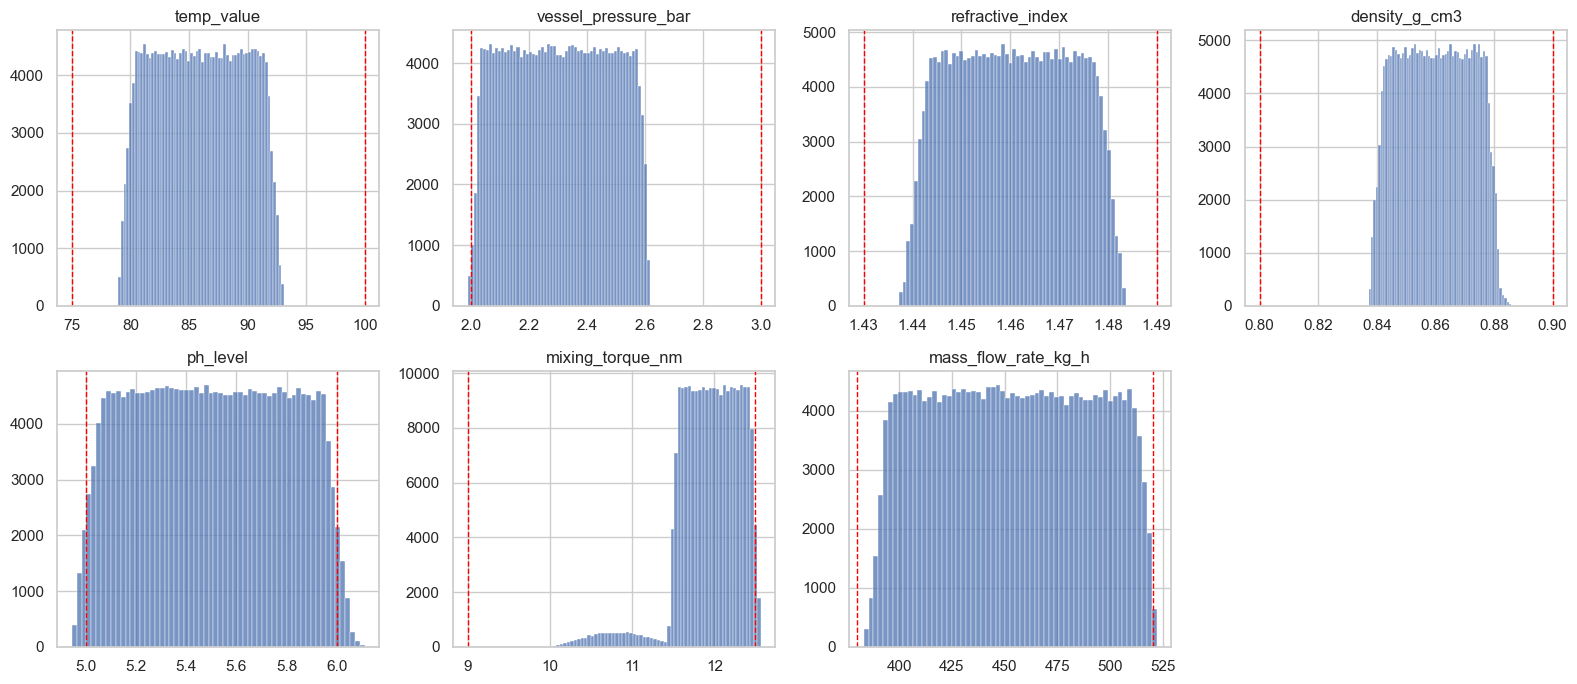

In [20]:
view = df.copy()
view.loc[view["temp_unit"] == "F", "temp_value"] = (view["temp_value"] - 32) * 5 / 9
ERROR_CODES = {"vessel_pressure_bar": -1, "density_g_cm3": 860, "ph_level": 14, "temp_value": 210}
for c, code_value in ERROR_CODES.items():
    view[c] = view[c].mask(view[c] == code_value)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, SENSORS):
    sns.histplot(view[c].dropna(), bins=60, ax=ax)
    lo, hi = RANGES["reaction_temperature_celsius" if c == "temp_value" else c]
    for v in (lo, hi):
        ax.axvline(v, ls="--", c="red", lw=1)
    ax.set(title=c, xlabel="", ylabel="")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

In [21]:
view[SENSORS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
temp_value,235504.0,85.954,3.696,78.956,82.773,85.944,89.141,93.126
vessel_pressure_bar,235681.0,2.308,0.170,1.989,2.161,2.308,2.455,2.620
refractive_index,236229.0,1.461,0.012,1.437,1.451,1.461,1.471,1.484
density_g_cm3,235599.0,0.860,0.012,0.837,0.850,0.860,0.870,0.886
ph_level,235720.0,5.503,0.291,4.945,5.254,5.502,5.753,6.111
mixing_torque_nm,236320.0,11.941,0.392,10.035,11.710,11.974,12.239,12.564
mass_flow_rate_kg_h,236038.0,453.559,36.897,383.250,421.858,453.350,485.356,521.925


Once error codes are removed, all sensors sit **inside or marginally beyond** their normal ranges — the process looks "in control" sensor by sensor,
which matches the Quality team's statement that their usual controls did not detect anything.

## 8. Target and derived columns

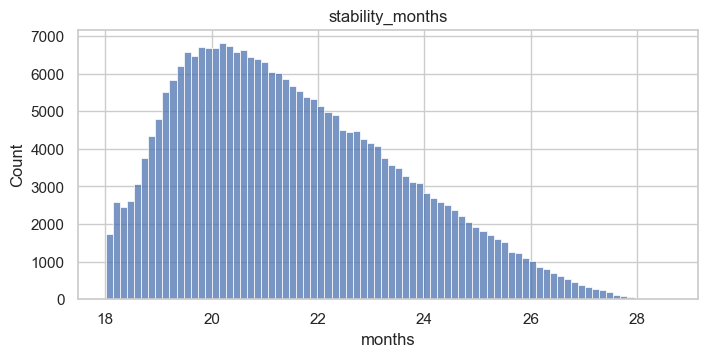

count    259200.00
mean         21.53
std           2.05
min          18.02
25%          19.91
50%          21.23
75%          22.91
max          28.61
Name: stability_months, dtype: float64

In [22]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(df[TARGET], bins=80, ax=ax)
ax.set(title="stability_months", xlabel="months")
plt.show()
df[TARGET].describe().round(2)

In [23]:
# Are purity_grade / oxidation_risk_flag just thresholds of the target? (leakage check)
display(df.groupby("purity_grade", observed=True)[TARGET].agg(["min", "max", "count"]).round(2))
display(df.groupby("oxidation_risk_flag")[TARGET].agg(["min", "max", "count"]).round(2))

,min,max,count
purity_grade,,,
Industrial Grade,20.00,25.00,172452
Perfumery Grade,25.00,28.61,17500
Technical Grade,18.02,20.00,69248


,min,max,count
oxidation_risk_flag,,,
False,21.00,28.61,140183
True,18.02,21.00,119017


Confirmed: Technical < 20 ≤ Industrial < 25 ≤ Perfumery, and risk flag = stability < 21.
They are **deterministic functions of the target** → excluded from any model (leakage), but useful to express impact in business terms.

## 9. Target vs. time, plant and reactor (first look at the problem)

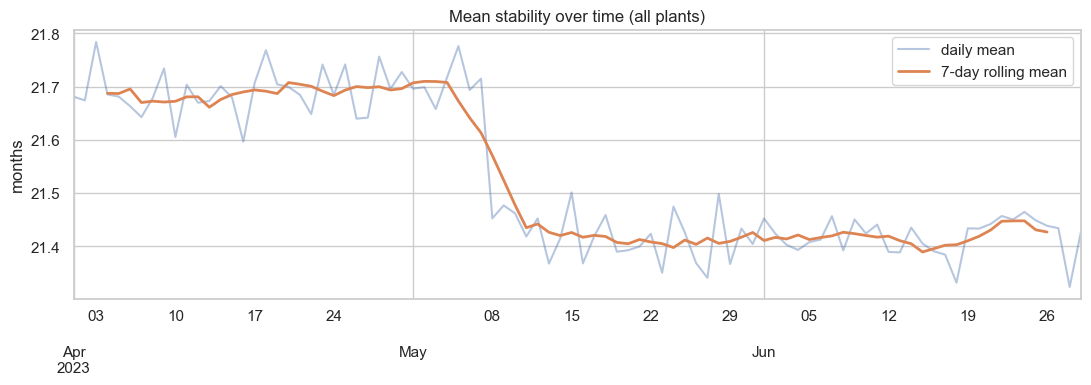

In [24]:
daily = df.groupby("date")[TARGET].mean()
fig, ax = plt.subplots(figsize=(13, 3.5))
daily.plot(ax=ax, alpha=0.4, label="daily mean")
daily.rolling(7, center=True).mean().plot(ax=ax, lw=2, label="7-day rolling mean")
ax.set(title="Mean stability over time (all plants)", ylabel="months", xlabel="")
ax.legend(); plt.show()

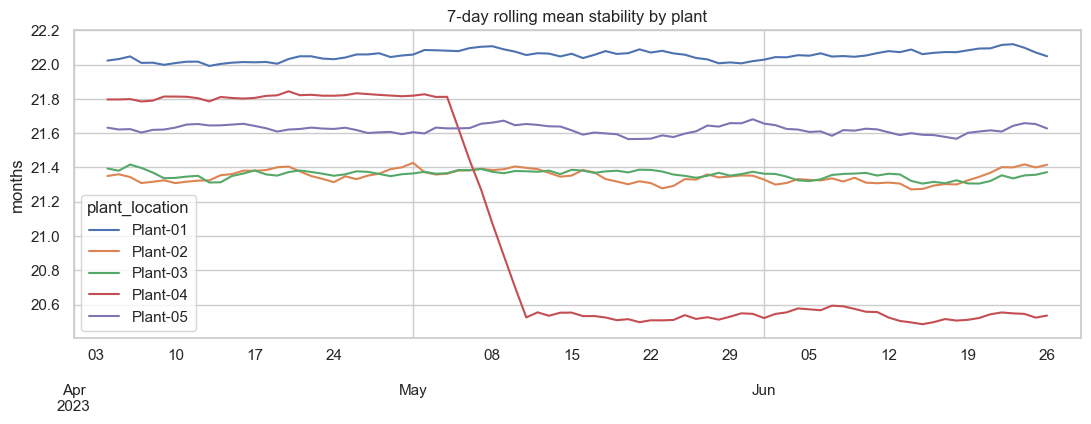

In [25]:
by_plant = df.pivot_table(index="date", columns="plant_location", values=TARGET, observed=True).rolling(7, center=True).mean()
by_plant.plot(figsize=(13, 4), title="7-day rolling mean stability by plant", ylabel="months", xlabel="")
plt.show()

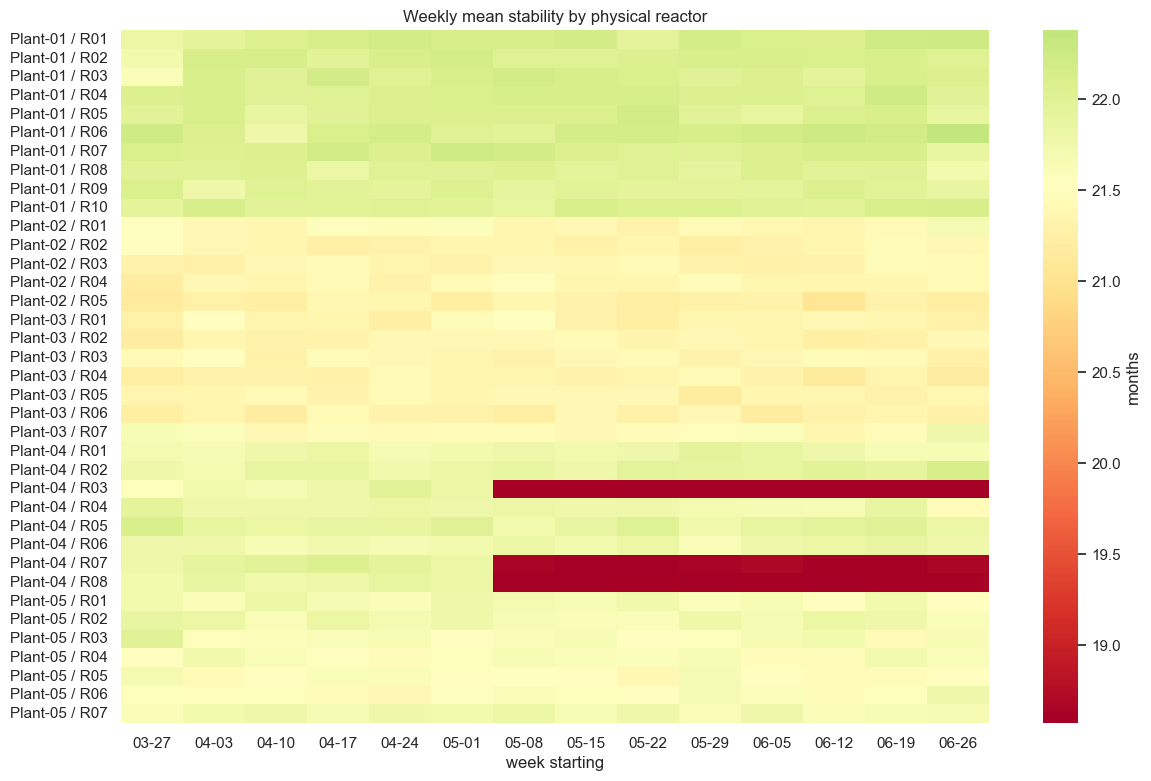

In [26]:
heat = df.assign(week=df["date"].dt.to_period("W").dt.start_time.dt.strftime("%m-%d")) \
         .pivot_table(index="reactor_key", columns="week", values=TARGET, observed=True)
fig, ax = plt.subplots(figsize=(14, 9))
sns.heatmap(heat, cmap="RdYlGn", center=df[TARGET].mean(), ax=ax, cbar_kws={"label": "months"})
ax.set(title="Weekly mean stability by physical reactor", xlabel="week starting", ylabel="")
plt.show()

The heatmap points to **three Plant-04 reactors (R03, R07, R08)** dropping abruptly in the week of 8 May. Pinning down the date and size:

In [27]:
AFFECTED = ["Plant-04 / R03", "Plant-04 / R07", "Plant-04 / R08"]
aff = df["reactor_key"].isin(AFFECTED)
display(df[aff].groupby("date")[TARGET].mean().loc["2023-05-04":"2023-05-11"].round(2).rename("affected reactors, daily mean"))

CUT = pd.Timestamp("2023-05-08")
period = np.where(df["date"] >= CUT, "from 2023-05-08", "before")
group = np.where(aff, "3 affected reactors", "other 34 reactors")
df.pivot_table(index=group, columns=period, values=TARGET, aggfunc="mean").round(2)[["before", "from 2023-05-08"]]

date
2023-05-04    21.87
2023-05-05    22.01
2023-05-06    21.62
2023-05-07    21.83
2023-05-08    18.59
2023-05-09    18.62
2023-05-10    18.61
2023-05-11    18.64
Name: affected reactors, daily mean, dtype: float64

,before,from 2023-05-08
3 affected reactors,21.85,18.61
other 34 reactors,21.68,21.68


## 10. Target vs. sensors

In [28]:
corr = view[SENSORS + [TARGET]].corr(method="spearman")[TARGET].drop(TARGET).sort_values()
corr.round(3).rename("Spearman ρ with stability").to_frame()

,Spearman ρ with stability
temp_value,-0.372
density_g_cm3,-0.042
ph_level,-0.031
vessel_pressure_bar,-0.009
mass_flow_rate_kg_h,-0.000
refractive_index,0.125
mixing_torque_nm,0.726


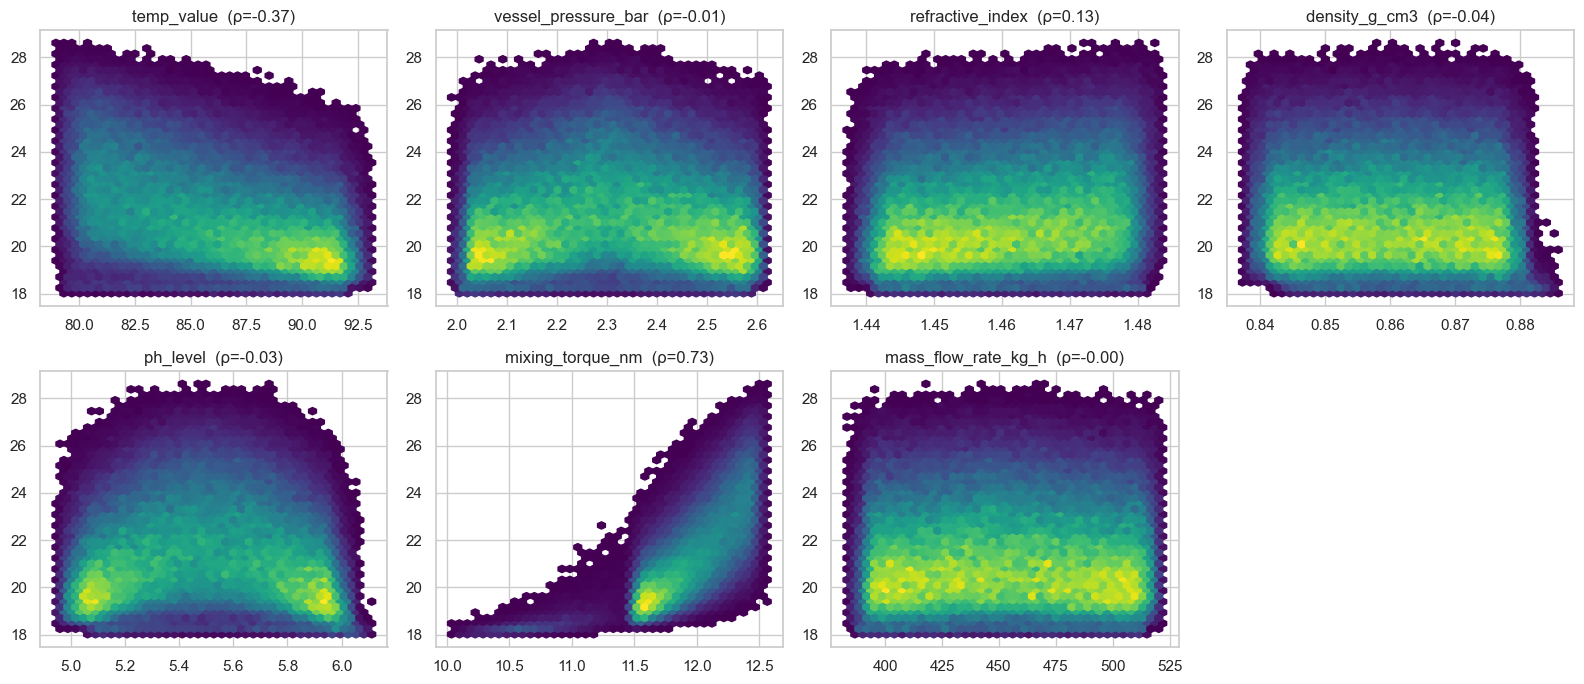

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, SENSORS):
    s = view[[c, TARGET]].dropna()
    ax.hexbin(s[c], s[TARGET], gridsize=40, cmap="viridis", mincnt=1)
    ax.set(title=f"{c}  (ρ={corr[c]:.2f})", xlabel="", ylabel="")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

Reading the plots, not just ρ:
- **Mixing torque** — strong positive relation, plus a **separate cluster of low torque (≈10–11.5 N·m)** with stability ≈ 18–19 months.
- **Temperature** — moderate negative relation (hotter → less stable), as chemistry suggests.
- **pH and pressure** — ρ ≈ 0, yet low-stability batches concentrate at **both ends** of the range (U-shape). Spearman only captures *monotonic* relations, so **ρ ≈ 0 does not mean "no effect"** → non-linear relations must be considered in phases 4 (e.g. tree models, SHAP).
- Refractive index, density, flow rate — no visible relation.

## 11. Summary of findings

**Data quality** (→ decisions in phase 3)
| ID | Finding | Extent |
|---|---|---|
| DQ-01 | 3 timestamp formats; slash = `dd/mm/yyyy` (unambiguous); slash/text have no time of day | ~25k rows |
| DQ-02 | Temperature in °F (Plant-04 only) | 1,506 rows |
| DQ-03 | One error code per sensor: −1 bar, 860 g/cm³, pH 14, 210 °C / 410 °F (Plant-04 only) | ~2.2k rows |
| DQ-03b | Marginal excursions just outside normal ranges (plausible real readings) | ~13k values |
| DQ-04 | ~9% missing per sensor, flat across plants/time, unrelated to target (MCAR-like) | ~9% / sensor |
| DQ-05 | Rows with **all** sensors missing — separate failure mechanism | ~5.3k rows |
| DQ-06 | `plant_country` redundant with `plant_location` | — |
| DQ-07 | `purity_grade`, `oxidation_risk_flag` = thresholds of target (leakage) | — |
| DQ-08 | Reactor IDs reused across plants → physical reactor = plant × reactor | 37 reactors |

**Problem — hypotheses to test (not conclusions)**
- **H3 (time) + H2 (where):** the drop is a **sudden step on 2023-05-08**, confined to **3 reactors of Plant-04 (R03, R07, R08)**: ≈ 21.9 → 18.6 months.
  All other 34 reactors are unchanged. The global "drop" seen on the overall mean is entirely explained by these 3 reactors.
- **H1 (process):** mixing torque (strong +, with a low-torque cluster) and temperature (moderate −) are most associated with stability; pH and pressure show **non-linear (U-shaped)** patterns that correlation misses.
- **Next (phase 4):** which sensor(s) changed in the 3 affected reactors on 2023-05-08?
- **H4 (artefact):** Plant-04 concentrates *all* sensor error codes and °F readings, and has the lowest stability — to be disentangled.